# Árboles de decisión — Impacto del diésel en SOBOCE S.A.
**Proyecto de Minería de Datos · Metodología CRISP-DM · Entrega: Modelo de árboles de decisión para clasificación**

*Integrantes: Wara Jhoseany Callejas Mullisaca · Isabel Belen Castillo Miranda · Arnold Rodrigo Villa Lopez · Abril Michelle Cayllagua Marca · Daniel Gustavo Zambrana Rondon*

---
## 1. Definición del problema y variable objetivo

### Contexto
Tras el DS 5676 (17-ago-2026) el diésel de SOBOCE pasó de Bs 3.75/L (subsidiado) a Bs 18.14/L. El KPI del proyecto es el **Costo del Diésel Operativo por Tonelada producida (CDO_Ton, Bs/Ton)**:

$$CDO\_Ton = \frac{Costo\_Diesel\_Total\_Bs}{Volumen\_Produccion\_Ton}$$

### Variable dependiente (binaria): `ALTO_CDO`
| Valor | Significado |
|---|---|
| **1** | Lote con CDO_Ton **mayor al percentil 75** histórico (lote *crítico*) |
| **0** | Lote con CDO_Ton normal (≤ P75) |

**¿Por qué esta variable?** El objetivo del proyecto es evaluar el impacto económico del incremento del diésel en los costos operativos. Clasificar los lotes como críticos / normales permite **caracterizar bajo qué condiciones se dispara el costo del combustible por tonelada**. Se usa el percentil 75 (≈ 27.85 Bs/Ton) y no la meta de 78.5 Bs/Ton, porque ésta solo la supera ~1 % de los registros (clases casi vacías). Se mantiene **la misma variable objetivo que en el modelo de regresión logística** para poder comparar ambos modelos en igualdad de condiciones.

### ¿Por qué un árbol de decisión?
- Produce **reglas «si… entonces…»** que se explican sin matemática a gerencia.
- No exige escalar variables ni asume relaciones lineales; captura **umbrales** (p. ej. «a partir de X km»).
- Detecta interacciones entre variables de forma automática.
- Contra: si crece sin control **memoriza** los datos (sobreajuste), por eso se controla su complejidad (sección 3).

### Variables independientes
| Variable | Justificación |
|---|---|
| `Precio_Diesel_Aplicado_SOBOCE_Bs_Litro` | Shock regulatorio (DS 5516 / DS 5676) |
| `Distancia_Prom_Transporte_Km` | El transporte es el 71.8 % del diésel total (EDA del documento) |
| `Volumen_Produccion_Ton` | Economías de escala |
| `Horas_Operacion_Maquinaria` | Consumo de maquinaria de planta/cantera (28.2 %) |
| `Num_Vehiculos_Transporte` | Tamaño de flota por despacho |
| `Planta`, `Region_Destino`, `Tipo_Cemento` | Diferencias estructurales (categóricas) |

**Excluidas:** consumos, costos y emisiones (`Consumo_Diesel_*`, `Costo_*`, `Emisiones_CO2_Ton`, `Margen_Bruto_Pct`) por **fuga de información** (son parte del KPI o su consecuencia); `Inflacion_Mensual_Pct` y `Tipo_Cambio_*` por colinealidad con el precio; `ID`, `Fecha`, `Pais`, `Empresa`, `Evento_Regulatorio` y `Categoria_*` por ser identificadores, constantes o redundantes.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, roc_auc_score, precision_recall_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

# --- Ruta del archivo de datos (ajustar si es necesario) ---
CANDIDATAS = [
    "Impacto_Diesel_Cementera_SOBOCE (2).xlsx",
    "Impacto_Diesel_Cementera_SOBOCE__2_.xlsx",
    "Data/Impacto_Diesel_Cementera_SOBOCE (2).xlsx",
    "/mnt/user-data/uploads/Impacto_Diesel_Cementera_SOBOCE__2_.xlsx",
]
RUTA = next((r for r in CANDIDATAS if os.path.exists(r)), None)
assert RUTA is not None, "No se encontró el archivo .xlsx: súbelo o corrige la lista CANDIDATAS."
print("Archivo de datos:", RUTA)

Archivo de datos: /mnt/user-data/uploads/Impacto_Diesel_Cementera_SOBOCE__2_.xlsx


---
## 2. Preparación de los datos
### 2.1 Carga y construcción de la variable objetivo

In [2]:
df = pd.read_excel(RUTA)
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (10000, 31)


,ID,Fecha,Pais,Empresa,Planta,Region_Destino,Tipo_Cemento,Categoria_Consumidor_Diesel,Categoria_Precio_Diesel,Evento_Regulatorio,...,Costo_Diesel_Total_Bs,Costo_Diesel_Total_USD,Costo_Transporte_Bs_Ton,Costo_Produccion_Bs_Ton,Precio_Venta_Cemento_Bs_Bolsa50kg,Margen_Bruto_Pct,Emisiones_CO2_Ton,Num_Vehiculos_Transporte,Horas_Operacion_Maquinaria,Inflacion_Mensual_Pct
0,1,2017-07-13,Bolivia,SOBOCE S.A.,Viacha (La Paz),Oruro,HE (Alta Resistencia),Gran Consumidor (GRACO),Único (subsidiado),Pre-shock: subsidio pleno vigente (~3.74 Bs/L ...,...,51793.33,7441.57,10.92,450.45,63.20,64.36,37.01,93,18.9,0.21
1,2,2017-07-13,Bolivia,SOBOCE S.A.,El Puente (Tarija),Santa Cruz,HE (Alta Resistencia),Gran Consumidor (GRACO),Único (subsidiado),Pre-shock: subsidio pleno vigente (~3.74 Bs/L ...,...,63913.17,9182.93,17.29,441.67,63.15,65.03,45.68,97,17.0,0.35
2,3,2017-07-13,Bolivia,SOBOCE S.A.,Warnes (Santa Cruz),Chuquisaca,IP-30,Gran Consumidor (GRACO),Único (subsidiado),Pre-shock: subsidio pleno vigente (~3.74 Bs/L ...,...,75933.98,10910.05,20.54,448.23,61.50,63.56,54.12,92,18.3,0.57
3,4,2017-07-14,Bolivia,SOBOCE S.A.,Viacha (La Paz),Chuquisaca,IP-40,Gran Consumidor (GRACO),Único (subsidiado),Pre-shock: subsidio pleno vigente (~3.74 Bs/L ...,...,37749.28,5423.75,9.59,444.42,59.98,62.95,26.98,82,18.4,0.68
4,5,2017-07-14,Bolivia,SOBOCE S.A.,El Puente (Tarija),Oruro,IP-30,Gran Consumidor (GRACO),Único (subsidiado),Pre-shock: subsidio pleno vigente (~3.74 Bs/L ...,...,52682.25,7569.29,14.53,432.76,63.54,65.94,37.55,85,18.4,0.69


In [3]:
# KPI del proyecto (Entrega 3): Costo del Diésel Operativo por Tonelada (CDO_Ton), en Bs/Ton
df["CDO_Ton"] = df["Costo_Diesel_Total_Bs"] / df["Volumen_Produccion_Ton"]

# Umbral: percentil 75 de la distribución histórica
UMBRAL = df["CDO_Ton"].quantile(0.75)
df["ALTO_CDO"] = (df["CDO_Ton"] > UMBRAL).astype(int)

print(f"Umbral (percentil 75 de CDO_Ton): {UMBRAL:.2f} Bs/Ton")
print(df["CDO_Ton"].describe().round(2))
print()
print(df["ALTO_CDO"].value_counts().rename({0: "Normal (0)", 1: "Alto CDO (1)"}))
print((df["ALTO_CDO"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

Umbral (percentil 75 de CDO_Ton): 27.85 Bs/Ton
count    10000.00
mean        25.41
std         13.26
min          8.15
25%         17.87
50%         22.20
75%         27.85
max        158.55
Name: CDO_Ton, dtype: float64

ALTO_CDO
Normal (0)      7500
Alto CDO (1)    2500
Name: count, dtype: int64
ALTO_CDO
0    75.0 %
1    25.0 %
Name: proportion, dtype: str


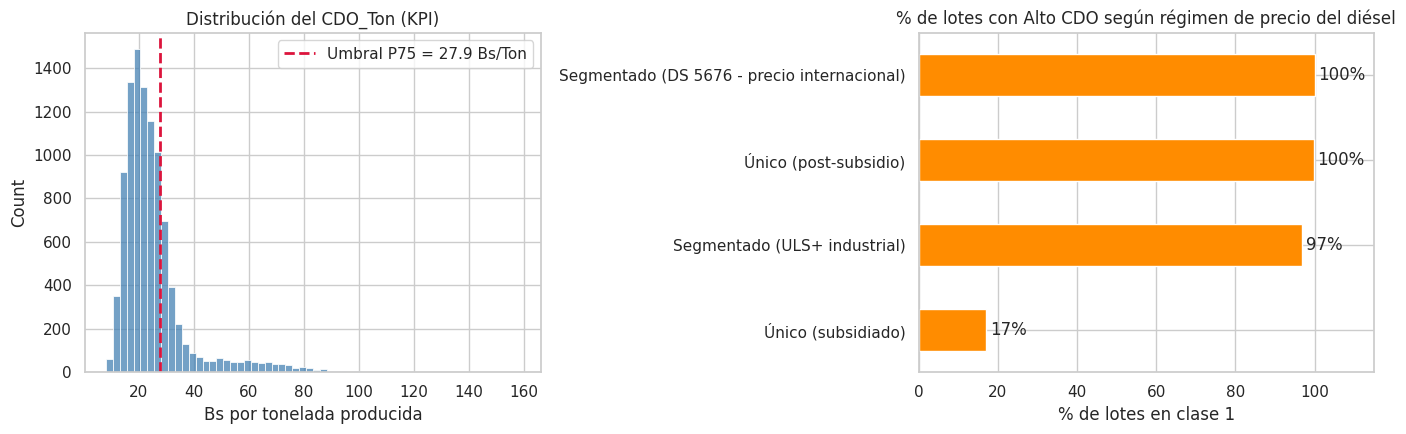

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (a) Distribución del KPI con el umbral
sns.histplot(df["CDO_Ton"], bins=60, color="steelblue", ax=axes[0])
axes[0].axvline(UMBRAL, color="crimson", ls="--", lw=2, label=f"Umbral P75 = {UMBRAL:.1f} Bs/Ton")
axes[0].set_title("Distribución del CDO_Ton (KPI)")
axes[0].set_xlabel("Bs por tonelada producida"); axes[0].legend()

# (b) % de lotes con Alto CDO por régimen tarifario
tab = (df.groupby("Categoria_Precio_Diesel")["ALTO_CDO"].mean() * 100).sort_values()
tab.plot(kind="barh", color="darkorange", ax=axes[1])
axes[1].set_title("% de lotes con Alto CDO según régimen de precio del diésel")
axes[1].set_xlabel("% de lotes en clase 1")
axes[1].set_ylabel("")
for i, v in enumerate(tab.values):
    axes[1].text(v + 1, i, f"{v:.0f}%", va="center")
axes[1].set_xlim(0, 115)
plt.tight_layout(); plt.show()

**Interpretación.** El umbral P75 ≈ **27.85 Bs/Ton** deja 2,500 lotes críticos (25 %) y 7,500 normales. El **100 % de los lotes con precios post-subsidio** son críticos, mientras que bajo el subsidio solo lo son ~17 %: el precio explica gran parte del problema y las rutas largas el resto.

### 2.2 Selección de variables y colinealidad

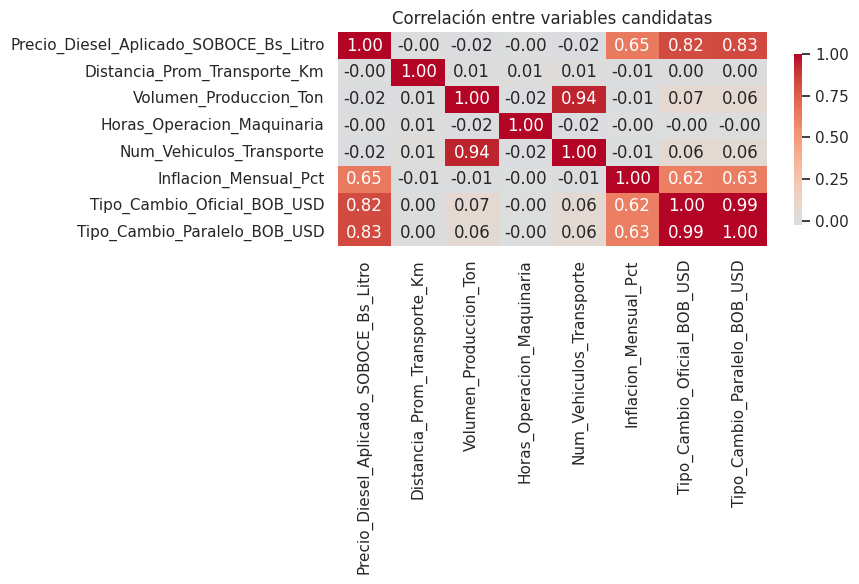

In [5]:
# Variables independientes elegidas
NUM = [
    "Precio_Diesel_Aplicado_SOBOCE_Bs_Litro",  # shock de precios (DS 5516 / DS 5676)
    "Distancia_Prom_Transporte_Km",            # logística (71.8% del diésel)
    "Volumen_Produccion_Ton",                  # economía de escala
    "Horas_Operacion_Maquinaria",              # maquinaria de planta/cantera (28.2%)
    "Num_Vehiculos_Transporte",                # tamaño de flota
]
CAT = ["Planta", "Region_Destino", "Tipo_Cemento"]

X = df[NUM + CAT].copy()
y = df["ALTO_CDO"].copy()

# Revisión de colinealidad entre candidatas numéricas (incluyendo las que se descartaron)
candidatas = NUM + ["Inflacion_Mensual_Pct", "Tipo_Cambio_Oficial_BOB_USD", "Tipo_Cambio_Paralelo_BOB_USD"]
plt.figure(figsize=(9, 6))
sns.heatmap(df[candidatas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"shrink": .8})
plt.title("Correlación entre variables candidatas")
plt.tight_layout(); plt.show()

**Interpretación.** Las variables operativas elegidas son casi independientes entre sí. La inflación y los tipos de cambio se mueven junto con el precio del diésel, por lo que se excluyen. *(Nota: a los árboles la colinealidad les afecta menos que a la regresión logística, pero se mantiene el mismo conjunto de variables para comparar.)*

### 2.3 Limpieza de nulos y duplicados

In [6]:
print("Nulos por variable seleccionada:")
print(X.isna().sum())
print("\nNulos en la variable objetivo:", y.isna().sum())
print("Filas duplicadas en el dataset:", df.duplicated().sum())

# Limpieza: eliminar filas con nulos (en este dataset no se espera ninguna) y duplicados
antes = len(df)
mask = X.notna().all(axis=1) & y.notna()
X, y = X[mask], y[mask]
print(f"\nFilas antes: {antes} | después de la limpieza: {len(X)}")

# Chequeo de rangos plausibles / valores atípicos extremos
X[NUM].describe().round(2)

Nulos por variable seleccionada:
Precio_Diesel_Aplicado_SOBOCE_Bs_Litro    0
Distancia_Prom_Transporte_Km              0
Volumen_Produccion_Ton                    0
Horas_Operacion_Maquinaria                0
Num_Vehiculos_Transporte                  0
Planta                                    0
Region_Destino                            0
Tipo_Cemento                              0
dtype: int64

Nulos en la variable objetivo: 0
Filas duplicadas en el dataset: 0

Filas antes: 10000 | después de la limpieza: 10000


,Precio_Diesel_Aplicado_SOBOCE_Bs_Litro,Distancia_Prom_Transporte_Km,Volumen_Produccion_Ton,Horas_Operacion_Maquinaria,Num_Vehiculos_Transporte
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,4.35,136.72,2568.89,18.00,83.08
std,1.89,50.13,324.03,2.54,11.17
min,3.70,20.00,1500.80,8.90,48.00
25%,3.74,98.10,2333.50,16.30,75.00
50%,3.75,131.55,2572.70,18.00,83.00
75%,3.76,172.00,2796.22,19.70,91.00
max,18.43,334.70,3834.90,27.50,135.00


**Interpretación.** El dataset no tiene nulos ni duplicados (10,000 → 10,000 filas). Los rangos son plausibles. Los árboles tampoco requieren tratar *outliers* ni escalar, porque solo comparan contra umbrales.

### 2.4 División en entrenamiento y prueba (80 / 20)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Entrenamiento: {X_train.shape[0]} filas | Prueba: {X_test.shape[0]} filas")
print("\nProporción de la clase 1 (Alto CDO):")
print(f"  Total: {y.mean():.3f} | Train: {y_train.mean():.3f} | Test: {y_test.mean():.3f}")

Entrenamiento: 8000 filas | Prueba: 2000 filas

Proporción de la clase 1 (Alto CDO):
  Total: 0.250 | Train: 0.250 | Test: 0.250


**Interpretación.** 8,000 filas para entrenar y 2,000 para evaluar, con `stratify=y` (25 % de lotes críticos en ambos) y `random_state=42` (reproducible).

---
## 3. Entrenamiento del árbol de decisión
### 3.1 Ajuste inicial del árbol con parámetros por defecto
**Codificación de categóricas:** One-Hot, para que cada planta/destino/tipo pueda usarse como regla. Las numéricas pasan sin escalar.

In [8]:
# Los árboles NO necesitan escalar variables numéricas (dividen por umbrales).
# Las categóricas sí deben codificarse: One-Hot (sin drop, para que cada categoría pueda usarse como regla).
preproc = ColumnTransformer([
    ("num", "passthrough", NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
])

# Árbol SIN restricciones: crece hasta clasificar perfectamente el entrenamiento
arbol_base = Pipeline([("prep", preproc), ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE))])
arbol_base.fit(X_train, y_train)

prof = arbol_base.named_steps["tree"].get_depth()
hojas = arbol_base.named_steps["tree"].get_n_leaves()
print(f"Profundidad: {prof} | Hojas: {hojas}")
print("Accuracy train:", round(arbol_base.score(X_train, y_train), 4))
print("Accuracy test :", round(arbol_base.score(X_test, y_test), 4))
print("F1 test       :", round(f1_score(y_test, arbol_base.predict(X_test)), 4))

Profundidad: 21 | Hojas: 343
Accuracy train: 1.0
Accuracy test : 0.9365
F1 test       : 0.8734


**Interpretación — sobreajuste.** El árbol sin límites crece hasta **21 niveles y 343 hojas** y logra **100 % en entrenamiento**, pero baja a **93.7 %** en prueba (F1 = 0.873). Aprendió el ruido de los datos, no solo el patrón. Hay que limitar su complejidad.

### 3.2 ¿Cuánta profundidad necesita el árbol?

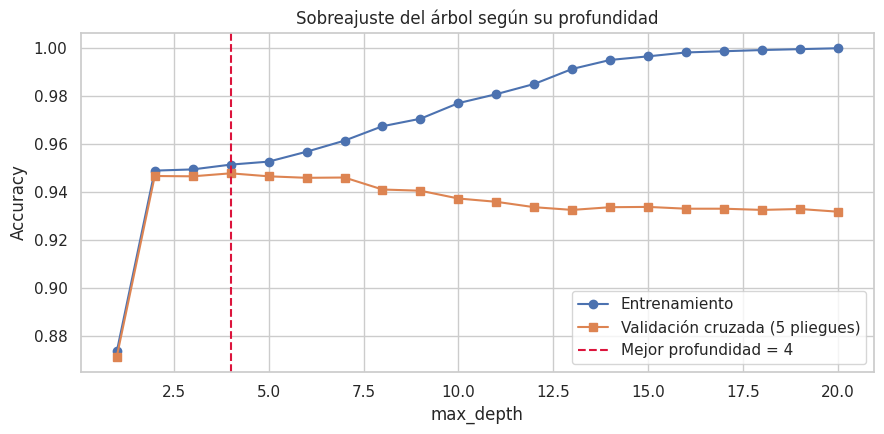

In [9]:
# Curva de validación: ¿cómo cambia el desempeño al permitir más profundidad?
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
profundidades = range(1, 21)
tr, va = [], []
for d in profundidades:
    m = Pipeline([("prep", preproc), ("tree", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))])
    tr.append(m.fit(X_train, y_train).score(X_train, y_train))
    va.append(cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy").mean())

plt.figure(figsize=(9, 4.5))
plt.plot(profundidades, tr, marker="o", label="Entrenamiento")
plt.plot(profundidades, va, marker="s", label="Validación cruzada (5 pliegues)")
mejor_d = list(profundidades)[int(np.argmax(va))]
plt.axvline(mejor_d, color="crimson", ls="--", label=f"Mejor profundidad = {mejor_d}")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.title("Sobreajuste del árbol según su profundidad")
plt.legend(); plt.tight_layout(); plt.show()

**Interpretación.** La precisión de entrenamiento sigue subiendo hasta 100 % (memorización), pero la de validación se estanca desde **profundidad 2** (≈ 94.7 %) y **desciende** pasada la profundidad 7 (≈ 93.4 % en 12). La curva casi plana de 2 a 7 indica que el patrón es muy simple: un árbol pequeño basta.

### 3.3 Ajuste de hiperparámetros (GridSearchCV)
Se prueban el criterio de impureza (`gini` / `entropy`), `max_depth`, `min_samples_leaf` (tamaño mínimo de hoja, otra forma de «podar») y el balanceo de clases, optimizando **F1** con validación cruzada estratificada de 5 pliegues.

In [10]:
pipe = Pipeline([("prep", preproc), ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE))])

param_grid = {
    "tree__criterion": ["gini", "entropy"],          # medida de impureza
    "tree__max_depth": [2, 3, 4, 5, 6, 8, 10],          # profundidad máxima
    "tree__min_samples_leaf": [1, 10, 30, 60],       # tamaño mínimo de hoja
    "tree__class_weight": [None, "balanced"],        # desbalance 75/25
}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1, refit=True)
grid.fit(X_train, y_train)

print("Mejores hiperparámetros:", grid.best_params_)
print(f"Mejor F1 en validación cruzada: {grid.best_score_:.4f}")
res = (pd.DataFrame(grid.cv_results_)
       [["param_tree__criterion", "param_tree__max_depth", "param_tree__min_samples_leaf",
         "param_tree__class_weight", "mean_test_score", "std_test_score"]]
       .sort_values("mean_test_score", ascending=False).head(8).round(4))
res

Mejores hiperparámetros: {'tree__class_weight': None, 'tree__criterion': 'gini', 'tree__max_depth': 2, 'tree__min_samples_leaf': 1}
Mejor F1 en validación cruzada: 0.8986


,param_tree__criterion,param_tree__max_depth,param_tree__min_samples_leaf,param_tree__class_weight,mean_test_score,std_test_score
0,gini,2,1,NaN,0.8986,0.0078
1,gini,2,10,NaN,0.8986,0.0078
2,gini,2,30,NaN,0.8986,0.0078
3,gini,2,60,NaN,0.8986,0.0078
7,gini,3,60,NaN,0.8986,0.0078
6,gini,3,30,NaN,0.8986,0.0078
10,gini,4,30,NaN,0.8983,0.0076
8,gini,4,1,NaN,0.8982,0.0063


**Interpretación.** La mejor configuración es un árbol **muy corto: `max_depth = 2`, criterio `gini`, sin ponderar clases**, con F1 CV ≈ 0.899. Varias combinaciones empatan (profundidades 2–4, hojas de 1 a 60 muestras, `gini`/`entropy`): el rendimiento es **robusto a los hiperparámetros**. Ante empates conviene el árbol más simple, que es el más fácil de explicar y el que menos se sobreajusta.

---
## 4. Evaluación del modelo
### 4.1 Métricas de clasificación
Se compara el árbol sin límites, el ajustado y la regresión logística (modelo anterior) con la misma partición.

In [11]:
arbol = grid.best_estimator_

# Regresión logística (modelo anterior) como punto de comparación
logreg = Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), NUM),
                                               ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT)])),
                   ("m", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]).fit(X_train, y_train)

def metricas(nombre, mdl, X_, y_):
    pred, proba = mdl.predict(X_), mdl.predict_proba(X_)[:, 1]
    return {"Modelo": nombre, "Accuracy": accuracy_score(y_, pred), "Precision": precision_score(y_, pred),
            "Recall": recall_score(y_, pred), "F1": f1_score(y_, pred), "ROC-AUC": roc_auc_score(y_, proba)}

tabla = pd.DataFrame([
    metricas("Árbol sin límites (train)", arbol_base, X_train, y_train),
    metricas("Árbol sin límites (test)", arbol_base, X_test, y_test),
    metricas("Árbol ajustado (train)", arbol, X_train, y_train),
    metricas("Árbol ajustado (test)", arbol, X_test, y_test),
    metricas("Regresión logística (test)", logreg, X_test, y_test),
]).set_index("Modelo").round(4)
tabla

,Accuracy,Precision,Recall,F1,ROC-AUC
Modelo,,,,,
Árbol sin límites (train),1.0000,1.0000,1.000,1.0000,1.0000
Árbol sin límites (test),0.9365,0.8708,0.876,0.8734,0.9163
Árbol ajustado (train),0.9489,0.8641,0.944,0.9023,0.9628
Árbol ajustado (test),0.9465,0.8579,0.942,0.8980,0.9613
Regresión logística (test),0.9435,0.8941,0.878,0.8860,0.9893


In [12]:
y_pred = arbol.predict(X_test)
y_proba = arbol.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred, target_names=["Normal (0)", "Alto CDO (1)"], digits=3))
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")

              precision    recall  f1-score   support

  Normal (0)      0.980     0.948     0.964      1500
Alto CDO (1)      0.858     0.942     0.898       500

    accuracy                          0.947      2000
   macro avg      0.919     0.945     0.931      2000
weighted avg      0.949     0.947     0.947      2000

TN = 1422 | FP = 78 | FN = 29 | TP = 471


**Interpretación (prueba, 2,000 lotes), árbol ajustado:**
- **Accuracy 94.7 %** (vs 75 % de un modelo que siempre dijera «normal»).
- **Recall 0.942:** detecta el 94 % de los lotes realmente críticos; solo se escapan **29**.
- **Precision 0.858:** cuando marca un lote como crítico acierta el 86 %; hay **78** falsas alarmas.
- **F1 0.898.** Matriz: TN = 1422, FP = 78, FN = 29, TP = 471.

**Comparación:** el árbol ajustado supera al árbol sin límites en prueba (F1 0.898 vs 0.873) y **a la regresión logística en recall (0.942 vs 0.878) y F1 (0.898 vs 0.886)**, con accuracy similar (0.947 vs 0.944). La regresión logística tiene **mejor precision (0.894 vs 0.858) y mucho mejor AUC (0.989 vs 0.961)**: ordena mejor los lotes por riesgo, porque un árbol de 4 hojas solo produce 4 probabilidades distintas. En ambos casos train ≈ test: sin sobreajuste.

### 4.2 Importancia de variables (feature importance)

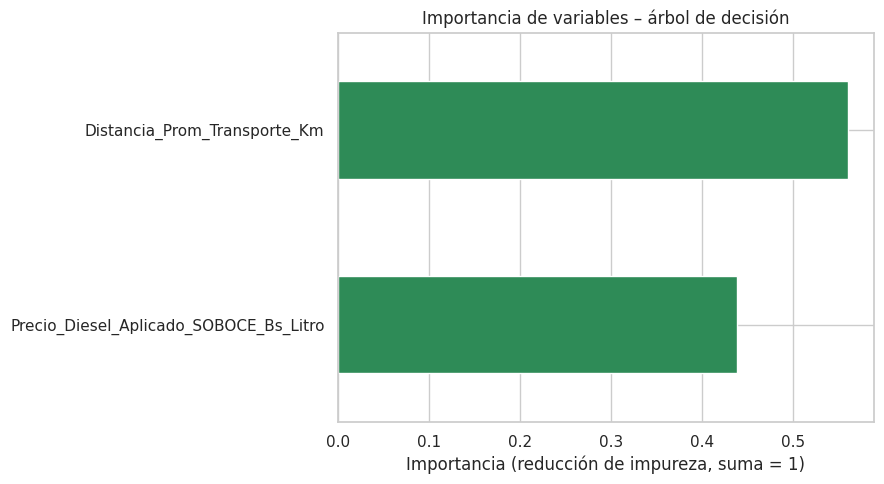

,importancia
Distancia_Prom_Transporte_Km,0.5613
Precio_Diesel_Aplicado_SOBOCE_Bs_Litro,0.4387


In [13]:
nombres = [n.split("__")[1] for n in arbol.named_steps["prep"].get_feature_names_out()]
modelo_arbol = arbol.named_steps["tree"]

imp = (pd.Series(modelo_arbol.feature_importances_, index=nombres)
       .sort_values(ascending=True))
imp = imp[imp > 0]
plt.figure(figsize=(9, 5))
imp.plot(kind="barh", color="seagreen")
plt.xlabel("Importancia (reducción de impureza, suma = 1)")
plt.title("Importancia de variables – árbol de decisión")
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(4).to_frame("importancia")

**Interpretación.** El árbol solo utiliza **dos variables**: la **distancia** (≈ 56 %) y el **precio del diésel** (≈ 44 %). El resto (volumen, horas de maquinaria, vehículos, planta, destino y tipo de cemento) tiene importancia 0 en este modelo. Coincide con la regresión logística, donde esas dos variables dominaban por amplio margen. *Las importancias de un árbol indican cuánto ayuda cada variable a separar las clases, no el tamaño del efecto causal.*

### 4.3 Análisis de errores por régimen de precio

In [14]:
an = X_test.copy()
an["real"] = y_test.values; an["pred"] = y_pred
an["Regimen"] = df.loc[X_test.index, "Categoria_Precio_Diesel"].values
an["error"] = (an["real"] != an["pred"]).astype(int)
an.groupby("Regimen").agg(lotes=("real", "size"), alto_cdo_real=("real", "mean"), tasa_error=("error", "mean")).round(3)

,lotes,alto_cdo_real,tasa_error
Regimen,,,
Segmentado (DS 5676 - precio internacional),7,1.000,0.000
Segmentado (ULS+ industrial),39,1.000,0.000
Único (post-subsidio),148,1.000,0.000
Único (subsidiado),1806,0.169,0.059


**Interpretación.** Igual que con la regresión logística, **no hay errores en los 194 lotes post-subsidio** (todos críticos y todos bien clasificados). Todos los errores (5.9 %) ocurren bajo el **régimen subsidiado**, justo en la frontera de las distancias cercanas a 182 km, donde la clase depende además del volumen de producción, una variable que el árbol corto no llega a usar.

---
## 5. Visualización y comunicación
### 5.1 Matriz de confusión y curva ROC

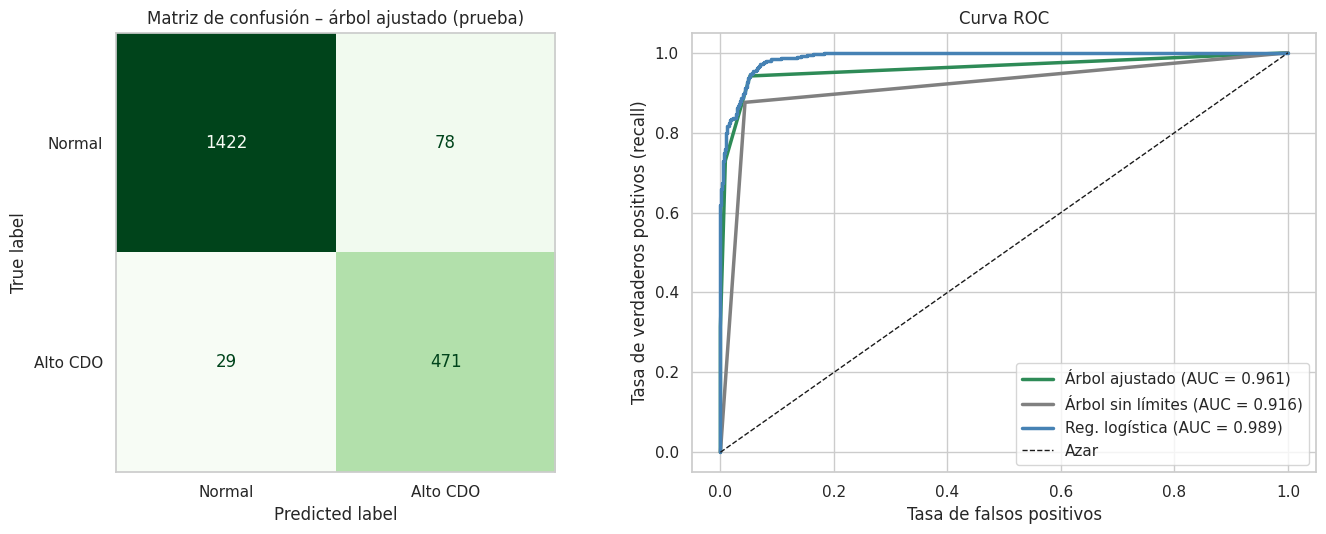

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Alto CDO"]).plot(ax=axes[0], cmap="Greens", colorbar=False, values_format="d")
axes[0].set_title("Matriz de confusión – árbol ajustado (prueba)"); axes[0].grid(False)

for nombre, mdl, color in [("Árbol ajustado", arbol, "seagreen"), ("Árbol sin límites", arbol_base, "gray"), ("Reg. logística", logreg, "steelblue")]:
    pr = mdl.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, pr)
    axes[1].plot(fpr, tpr, lw=2.5, color=color, label=f"{nombre} (AUC = {roc_auc_score(y_test, pr):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Azar")
axes[1].set_xlabel("Tasa de falsos positivos"); axes[1].set_ylabel("Tasa de verdaderos positivos (recall)")
axes[1].set_title("Curva ROC"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

**Interpretación.** La diagonal domina la matriz de confusión. En la ROC, la **regresión logística (AUC 0.989)** queda por encima del **árbol ajustado (AUC 0.961)**; la curva del árbol tiene forma de escalón porque solo hay cuatro niveles de probabilidad. El árbol sin límites tiene AUC 0.916: es el peor en generalización.

### 5.2 El árbol de decisión y sus reglas

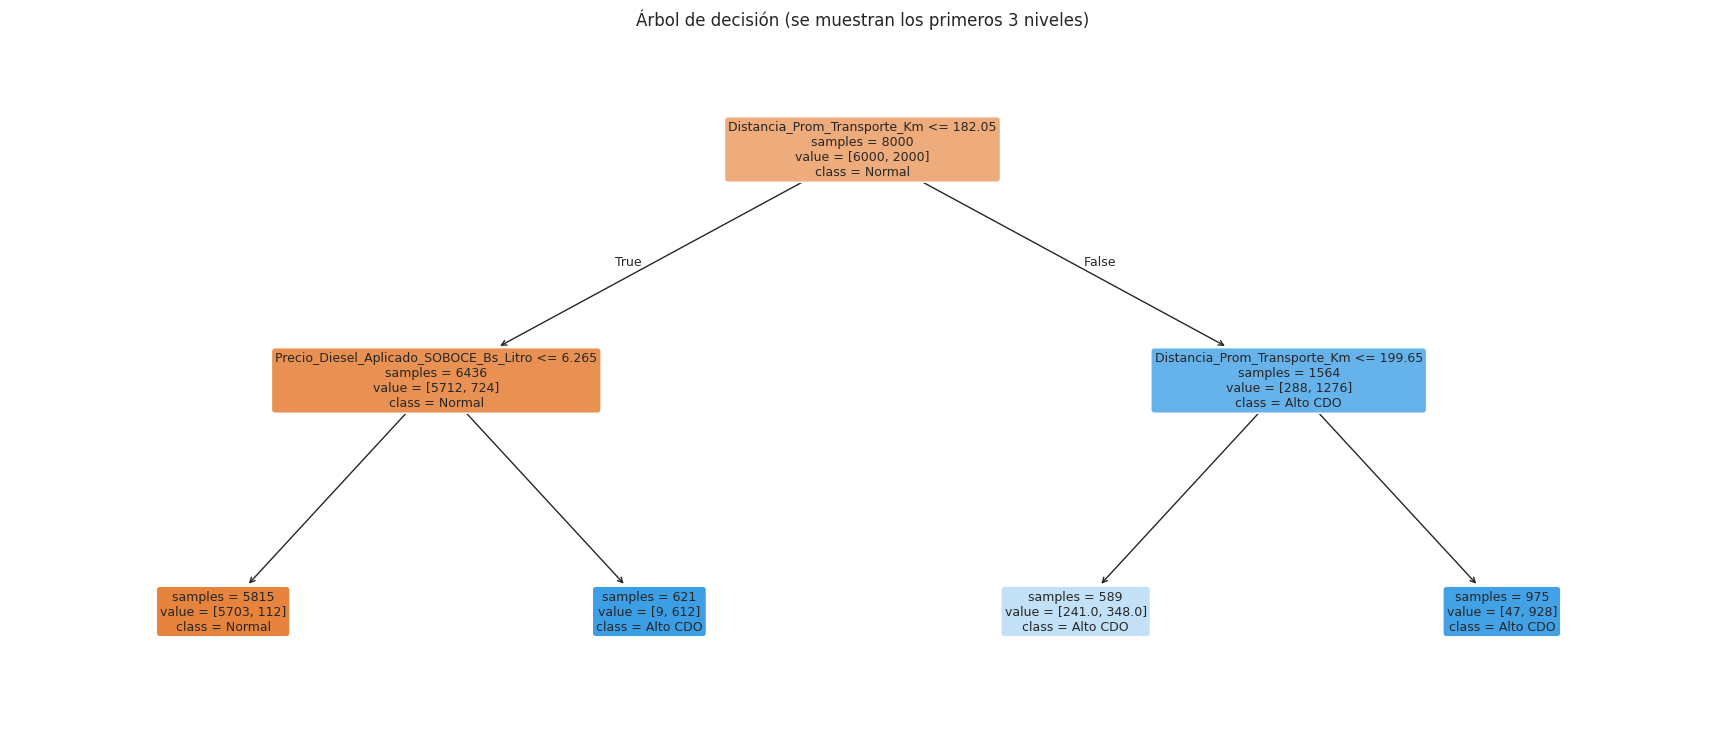

Profundidad real del árbol: 2 | Hojas: 4


In [16]:
nombres = [n.split("__")[1] for n in arbol.named_steps["prep"].get_feature_names_out()]
modelo_arbol = arbol.named_steps["tree"]

plt.figure(figsize=(22, 9))
plot_tree(modelo_arbol, feature_names=nombres, class_names=["Normal", "Alto CDO"], filled=True, rounded=True,
          max_depth=3, fontsize=9, proportion=False, impurity=False)
plt.title("Árbol de decisión (se muestran los primeros 3 niveles)")
plt.show()
print(f"Profundidad real del árbol: {modelo_arbol.get_depth()} | Hojas: {modelo_arbol.get_n_leaves()}")

In [17]:
# Reglas del árbol en texto (primeros niveles) – fáciles de comunicar a gerencia
print(export_text(modelo_arbol, feature_names=nombres, max_depth=3))

|--- Distancia_Prom_Transporte_Km <= 182.05
|   |--- Precio_Diesel_Aplicado_SOBOCE_Bs_Litro <= 6.26
|   |   |--- class: 0
|   |--- Precio_Diesel_Aplicado_SOBOCE_Bs_Litro >  6.26
|   |   |--- class: 1
|--- Distancia_Prom_Transporte_Km >  182.05
|   |--- Distancia_Prom_Transporte_Km <= 199.65
|   |   |--- class: 1
|   |--- Distancia_Prom_Transporte_Km >  199.65
|   |   |--- class: 1



**Lectura del árbol (reglas de negocio):**
1. **Si la distancia de transporte es > 182 km → lote crítico**, sin importar el precio.
2. **Si la distancia es ≤ 182 km y el precio del diésel es > Bs 6.26/L → crítico.** (Todos los precios post-subsidio, de Bs 8.8 a 18.1, superan ese umbral.)
3. **Si la distancia es ≤ 182 km y el precio ≤ Bs 6.26/L → normal.**

En el nodo derecho aparecen divisiones adicionales que solo refinan la pureza pero **no cambian la clase** (todas terminan en «crítico»).

**Significado:** bajo el régimen subsidiado solo las **rutas largas** (> 182 km, p. ej. El Puente hacia destinos lejanos) generan lotes críticos; bajo el nuevo régimen de precios **cualquier lote** lo es. El shock de precio vuelve «crítico» incluso al transporte corto.

### 5.3 Explicación de los hallazgos para la gerencia y conclusiones

**En palabras simples:** el costo del diésel por tonelada de SOBOCE se vuelve «alto» por dos motivos: (1) **rutas largas** (más de 182 km) y (2) **el nuevo precio del diésel** (más de Bs 6.26/L). Desde el decreto, el segundo motivo alcanza a **todos** los despachos, incluso a los de distancias cortas.

**Conclusiones**
- Un árbol de **solo 2 niveles (4 hojas)** clasifica correctamente el 94.7 % de los lotes (F1 = 0.898, recall = 0.942) y **supera a la regresión logística en detección de lotes críticos**; la regresión logística supera al árbol en precisión y capacidad de ordenar por riesgo (AUC).
- Un árbol sin control **se sobreajusta** (100 % train → 93.7 % test); limitar `max_depth` / `min_samples_leaf` es indispensable.
- Las reglas son claras: **distancia > 182 km o precio > Bs 6.26/L** ⇒ lote crítico. El impacto del decreto se manifiesta como un desplazamiento de todo el nivel del costo del diésel por tonelada, no solo de algunos lotes.
- **¿Cuál usar?** Para comunicar reglas y priorizar la detección: el árbol. Para estimar probabilidades de riesgo y ordenar lotes: la regresión logística.

**Limitaciones**
- Datos **sintéticos**; el patrón tan simple (2 variables bastan) refleja las reglas con que se generaron y probablemente sería más complejo con datos reales.
- Solo ~10 % de los registros son post-subsidio; la partición aleatoria mezcla períodos. Una validación **temporal** sería más exigente.
- La definición de «crítico» (P75) es una decisión de negocio.
- El documento de Fase 1 reporta 341 registros bajo el DS 5676, pero la base tiene 34.

**Siguientes pasos:** probar *Random Forest* / *XGBoost* (previstos en el documento de Fase 1) para comparar con ambos modelos, y el clustering de rutas.